<a href="https://colab.research.google.com/github/mukul2508/UCS420_MUKUL-_BANSAL_1024170294/blob/main/Assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q landingai pillow matplotlib gTTS

In [ ]:
%pip install landingai

In [ ]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 11.3.0
JPEG encoding successful: 633 bytes


In [ ]:

from google.colab import userdata
from landingai.predict import Predictor

API_KEY = "land_sk_QPc9WTCDMSyQCcjwYnI7d7XiSXy4RyJ275BPVLq9oD4eADRV11"

ENDPOINT_ID = "5187c2eb-6a8c-4d66-92eb-527ac0368ec9"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized.")


LandingAI predictor initialized.


In [ ]:

from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving Screenshot 2026-11-18 215505.png to Screenshot 2026-11-18 215505.png
Image size: (420, 585)
Image array shape: (585, 420, 3)


In [ ]:

predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)


Prediction count: 0


Wildfire Cognitive Assistant
Upload an image for analysis.


Saving fire.jpg to fire (4).jpg


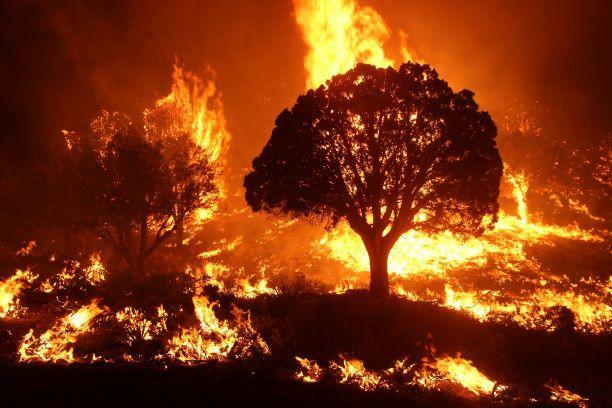


Raw model predictions:
[]
No predictions returned by the model.


In [ ]:

from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io

def wildfire_assistant():

    print("Wildfire Cognitive Assistant")
    print("Upload an image for analysis.")

    # 1. Upload image
    uploaded = files.upload()
    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nRaw model predictions:")
    print(predictions)

    if not predictions:
        print("No predictions returned by the model.")
        return

    # 3. Read the ClassificationPrediction object
    prediction = predictions[0]

    predicted_label = getattr(prediction, "label_name", None)
    predicted_index = getattr(prediction, "label_index", None)
    confidence = getattr(prediction, "score", None)

    print("Predicted label:", predicted_label)
    print("Predicted class index:", predicted_index)
    print("Confidence:", confidence)

    # 4. Interpret the model's class index
    # Assumption: index 1 = Fire, index 0 = No Fire
    if predicted_index == 1:
        result = "Fire! Fire!"
        print("🔥 FIRE DETECTED!")
    elif predicted_index == 0:
        result = "Safe"
        print("No-fire class predicted.")
    else:
        result = "Unable to determine"
        print("Unknown class index.")

    display(Markdown(f"### Assistant response: **{result}**"))

    # 5. Generate audio response
    if result != "Unable to determine":
        speech = gTTS(text=result, lang="en")
        speech.save("wildfire_response.mp3")

        display(Audio("wildfire_response.mp3", autoplay=False))
        files.download("wildfire_response.mp3")


wildfire_assistant()
